In [ ]:
import marimo as mo

# Node Classification with Additional Node Features

*August 4 2026*
*Training Workshop: Introduction to Deep Graph Learning*
*Ingo Scholtes, CAIDAS, Julius-Maximilians-Universität Würzburg (JMU), Germany*

In the previous notebooks, we have considered networks where nodes did not have additional features, i.e. we used a one-hot encoding of the nodes as input to our GCN. With this approach, the GCN can only learn based on patterns contained in the graph topology. But what if we have additional features that could help the GCN, e.g., to classify nodes? Here we demonstrate this important capability of graph convolutional networks.

In [ ]:
import numpy as np
import seaborn as sns
import torch
import torch_geometric
from matplotlib import pyplot as plt
from sklearn.decomposition import TruncatedSVD
from torch.nn.functional import one_hot as ohe

import pathpyG as pp

plt.style.use('default')
sns.set_style("whitegrid")

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Running on', device)

Running on cpu


We first use `pathpyG` to generate the synthetic network shown on slide 29.

In [ ]:
n = 50

random_1 = pp.algorithms.generative_models.watts_strogatz(n=n, s=4, p=0.01, mapping=pp.IndexMap([str(x) for x in range(n)]), undirected=True)
random_2 = pp.algorithms.generative_models.watts_strogatz(n=n, s=4, p=0.01, mapping=pp.IndexMap([str(x+1*n) for x in range(n)]), undirected=True)

network = random_1 + random_2
network = network.to_undirected()

# node features, cluster labels, and targets are assigned after merging and undirecting the
# graph, since to_undirected() does not preserve custom node attributes set beforehand
network.data.x = torch.cat((torch.tensor([0.]*int(n/2)), torch.tensor([1.]*int(n/2)),
                             torch.tensor([0.]*int(n/2)), torch.tensor([1.]*int(n/2))))
network.data.cluster = torch.cat((torch.tensor([0]*int(n/2)), torch.tensor([1]*int(n/2)),
                                   torch.tensor([2]*int(n/2)), torch.tensor([3]*int(n/2))))
network.data.y = torch.cat((torch.tensor([[0,0]]*int(n/2)), torch.tensor([[0,1]]*int(n/2)),
                             torch.tensor([[1,0]]*int(n/2)), torch.tensor([[1,1]]*int(n/2)))).float()

# randomly update src and tgt in network.edge_index so that link source in random_1 to target in random_2 and vice-versa
src_indices = torch.where(network.data.cluster < 2)[0]
tgt_indices = torch.where(network.data.cluster >= 2)[0]
num_edges_to_update = 10
edge_indices_to_update = np.random.choice(network.data.edge_index.shape[1], num_edges_to_update, replace=False)
for edge_index in edge_indices_to_update:
    src, tgt = network.data.edge_index[:, edge_index]
    if src in src_indices and tgt in src_indices:
        new_tgt = np.random.choice(tgt_indices.cpu().numpy())
        network.data.edge_index[1, edge_index] = new_tgt
    elif src in tgt_indices and tgt in tgt_indices:
        new_src = np.random.choice(src_indices.cpu().numpy())
        network.data.edge_index[0, edge_index] = new_src

network.data.x = torch.cat((network.data.x.unsqueeze(1), ohe(torch.arange(0,2*n))), dim=1)

pp.plot(network, edge_color='gray');

<iframe srcdoc='<style>
.label-text {
 fill: #969595;
 font-size: 16px;
 font-family: sans-serif;
}
</style>

<div id = "x6c12788b8d8a4aa88fdd5de6e7008543"> </div>
<script charset="utf-8">
function render_plot_393e28498ac34ef1bd6c184e2ea27b8a() {
 const d3 = window.d3;
 if (!d3) { console.error('D3 not loaded'); return; }
const data = {"nodes": [{"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "0"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "1"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "10"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "11"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "12"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "13"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "14"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "15"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "16"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "17"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "18"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "19"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "2"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "20"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "21"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "22"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "23"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "24"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "25"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "26"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "27"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "28"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "29"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "3"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "30"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "31"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "32"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "33"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "34"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "35"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "36"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "37"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "38"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "39"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "4"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "40"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "41"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "42"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "43"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "44"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "45"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "46"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "47"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "48"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "49"}, {"color": "#244a5c", "size": 15, "opacity": 0.75, "image": null, "uid": "5"}, {"color": "#244a5c", "si

We reuse the implementation of the GCN from the previous notebook:

In [ ]:
class GraphConvolution(torch_geometric.nn.MessagePassing):
    """A graph convolution layer following (Kipf, Welling 2017)."""
    # Arguments passed to `propagate()`. pyG usually infers them from the source code of the class,
    # which is not possible for classes defined in marimo notebooks
    propagate_type = {'x': torch.Tensor, 'norm': torch.Tensor}

    def __init__(self, in_ch, out_ch):
        """Initialize the layer parameters."""
        super().__init__(aggr='add')

        # this linear function is used to transform node features 
        # into messages that are then "sent" to neighbors
        self.linear = torch.nn.Linear(in_ch, out_ch)
    
    def forward(self, x, edge_index):
        """Perform a graph convolution.

        This function uses the edges captured in edge_index, performs
        the graph convolution function according to (Kipf, Welling 2017)
        and propagates the transformed features along the edges of the graph.
        """
        # by adding self-loops, we ensure that aggregated messages from neighbors 
        # are combined with information from the node itself
        # this corresponds to matrix $\tilde{A}$ in (Kipf, Welling 2017)
        edge_index, _ = torch_geometric.utils.add_self_loops(edge_index, num_nodes=x.size(0))

        # we linearly transform the features of *all* nodes stored in x
        x = self.linear(x)

        # extract the source and target nodes of all edges
        source, target = edge_index
    
        # compute the (in-)degrees $d_i$ of source nodes
        deg = torch_geometric.utils.degree(target, x.size(0), dtype=x.dtype)
        deg_inv_sqrt = deg.pow(-0.5)
        deg_inv_sqrt[deg_inv_sqrt == float('inf')] = 0

        # with this, the normalization to be applied in the propagation step can be expressed as
        # this corresponds to D^{-0.5} A * D^{-0.5} in (Kipf, Welling 2017)
        norm = deg_inv_sqrt[source] * deg_inv_sqrt[target]
    
        # the propagate function propagates messages along the edges of the graph
        # this function internally calls the functions: message(), aggregate() and update()
        # the normalization is applied in the message() function
        return self.propagate(edge_index, x=x, norm=norm)

    def message(self, x_j, norm):
        """Construct the message that is sent along each edge."""
        # x_j is a so-called **lifted** tensor which contains the source node features of each edge, 
        # i.e. it has a shape (m, out_ch) where m is the number of edges

        # a call to view(-1, 1) returns a reshaped tensor, where the second dimension 
        # is one and the first dimension is inferred automatically
        return norm.view(-1,1) * x_j

In [ ]:
class GCN(torch.nn.Module):
    """A two-layer graph convolutional network."""

    def __init__(self, data: torch_geometric.data.Data, out_ch, hidden_dim=16):
        """Initialize the model parameters."""
        super().__init__()

        self.input_to_hidden = GraphConvolution(data.num_node_features, hidden_dim)
        self.hidden_to_output =  GraphConvolution(hidden_dim, out_ch)
    
    def forward(self, x, edge_index):
        """Compute class probabilities for all nodes."""
        # first graph convolution -> map nodes to representations in hidden_dim dimensions
        x = self.input_to_hidden(x, edge_index)

        # non-linear activation function
        x = torch.sigmoid(x)

        # graph convolution -> maps node representations to output classes
        x = self.hidden_to_output(x, edge_index)

        return torch.sigmoid(x)

In [ ]:
transform = torch_geometric.transforms.RandomNodeSplit(split='train_rest', num_val=0.3, num_test=0)
data = transform(network.data)

print(data)

Data(edge_index=[2, 798], num_nodes=100, x=[100, 101], cluster=[100], y=[100, 2], train_mask=[100], val_mask=[100], test_mask=[100])


In [ ]:
model = GCN(data, out_ch=2, hidden_dim=4)

epochs = 200
lrn_rate = 0.1

optimizer = torch.optim.SGD(model.parameters(), lr=lrn_rate)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199


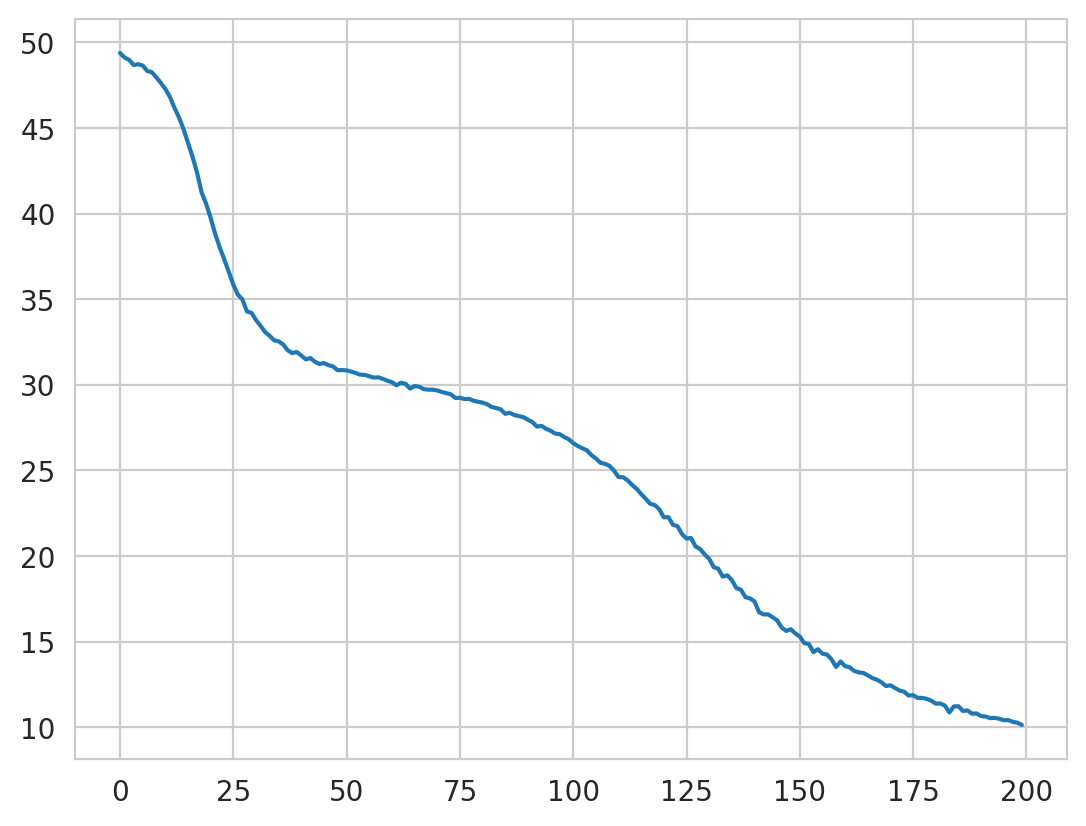

In [ ]:
indices = np.arange(100)
losses = []
model.train()
for epoch in range(epochs):
    error = 0
    print(epoch)
    np.random.shuffle(indices)
    for i in indices:
        if data.train_mask[i]:
            optimizer.zero_grad()
            _output = model(network.data.x, network.data.edge_index)
            loss = torch.nn.functional.binary_cross_entropy(_output[i], data.y[i])
            loss.backward()
            optimizer.step()
            error += loss.detach().numpy()
    losses.append(error)  # set gradients to zero
# plot evolution of loss function
plt.plot(range(epochs), losses)  # compute loss function for training sample and backpropagate  # update parameters

In [ ]:
_output = model.forward(network.data.x, network.data.edge_index)
prediction = _output.round().long()
# we efficiently map probabilities to classes by rounding values to the 
# nearest integer, i.e. we obtain class 0 for probabilities smaller than 0.5
# and class 1 for probabilities larger than 0.5
print(prediction)

tensor([[0, 0],
        [0, 0],
        [1, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 0],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 0],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 1],
        [0, 0],
        [1, 1],
        [1, 1],
        [1, 1],
        [1, 1],
        [1, 1],
        [1, 0],
        [1, 0],
        [1, 0],
        [1, 0],
        [1, 0],
        [1, 0],
        [1, 0],
        [1, 0],
        [1, 0],
        [1, 0],
        [1, 0],
        

In [ ]:
_colors = {}
for _v in network.nodes:
    _index = network.mapping.to_idx(_v)
    if data.val_mask[_index]:
        if torch.equal(prediction[_index], torch.tensor([0, 0])):
            _colors[_v] = 'blue'
        elif torch.equal(prediction[_index], torch.tensor([0, 1])):
            _colors[_v] = 'orange'
        elif torch.equal(prediction[_index], torch.tensor([1, 0])):
            _colors[_v] = 'magenta'
        else:
            _colors[_v] = 'cyan'
    else:
        _colors[_v] = 'gray'
pp.plot(network, edge_color='gray', node_color=_colors);

<iframe srcdoc='<style>
.label-text {
 fill: #969595;
 font-size: 16px;
 font-family: sans-serif;
}
</style>

<div id = "xf11231614a6f4e85aa34d555b777251e"> </div>
<script charset="utf-8">
function render_plot_fa18b0cafb8d43cf90e7e856082760fb() {
 const d3 = window.d3;
 if (!d3) { console.error('D3 not loaded'); return; }
const data = {"nodes": [{"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "0"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "1"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "10"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "11"}, {"color": "#0000ff", "size": 15, "opacity": 0.75, "image": null, "uid": "12"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "13"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "14"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "15"}, {"color": "#0000ff", "size": 15, "opacity": 0.75, "image": null, "uid": "16"}, {"color": "#0000ff", "size": 15, "opacity": 0.75, "image": null, "uid": "17"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "18"}, {"color": "#0000ff", "size": 15, "opacity": 0.75, "image": null, "uid": "19"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "2"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "20"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "21"}, {"color": "#0000ff", "size": 15, "opacity": 0.75, "image": null, "uid": "22"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "23"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "24"}, {"color": "#0000ff", "size": 15, "opacity": 0.75, "image": null, "uid": "25"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "26"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "27"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "28"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "29"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "3"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "30"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "31"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "32"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "33"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "34"}, {"color": "#ffa500", "size": 15, "opacity": 0.75, "image": null, "uid": "35"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "36"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "37"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "38"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "39"}, {"color": "#0000ff", "size": 15, "opacity": 0.75, "image": null, "uid": "4"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "40"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "41"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "42"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "43"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "44"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "45"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "46"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "47"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "48"}, {"color": "#808080", "size": 15, "opacity": 0.75, "image": null, "uid": "49"}, {"color": "#0000ff", "size": 15, "opacity": 0.75, "image": null, "uid": "5"}, {"color": "#00ffff", "si

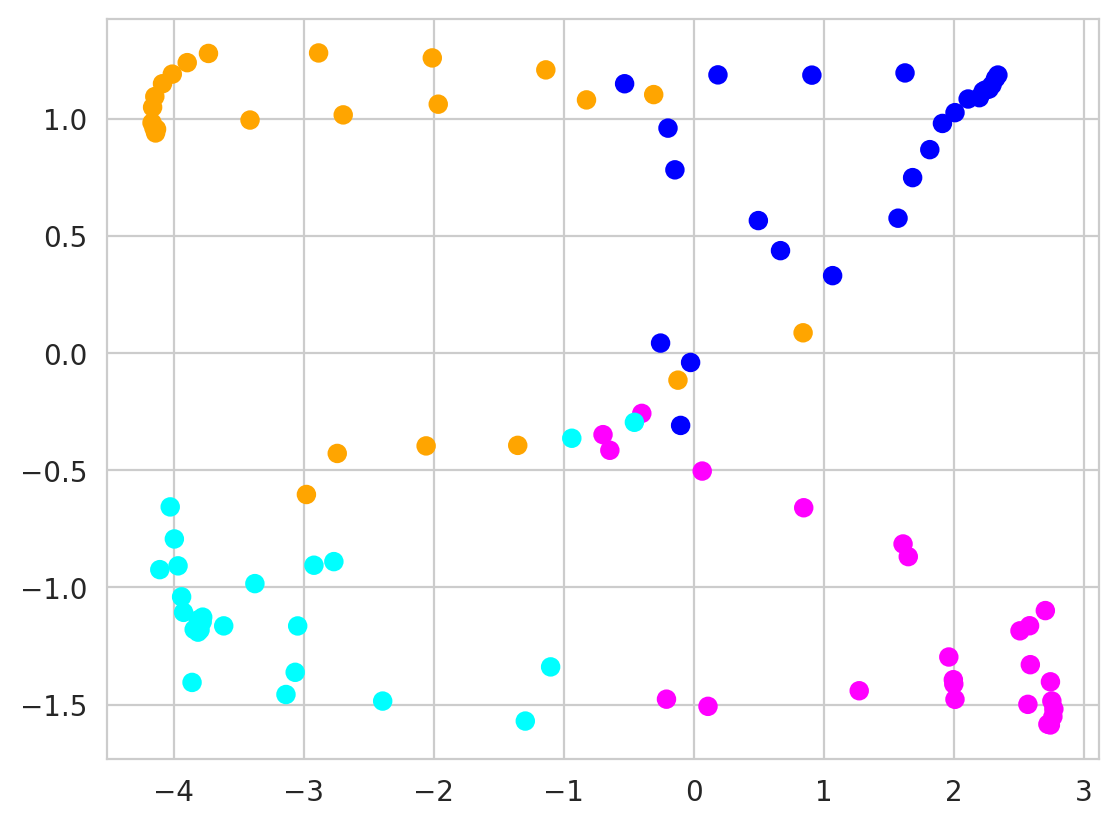

In [ ]:
embedding = model.input_to_hidden.forward(network.data.x, network.data.edge_index)
svd = TruncatedSVD()
low_dim = svd.fit_transform(embedding.detach().numpy())
_colors = {}
for _v in network.nodes:
    _index = network.mapping.to_idx(_v)
    if data.cluster[_index] == 0:
        _colors[_index] = 'blue'
    elif data.cluster[_index] == 1:
        _colors[_index] = 'orange'
    elif data.cluster[_index] == 2:
        _colors[_index] = 'magenta'
    else:
        _colors[_index] = 'cyan'
plt.clf()
plt.scatter(low_dim[:, 0], low_dim[:, 1], c=_colors.values())